<h1 align="center">Лабораторна робота №1</h1>
<h2 align="center">Базові алгоритми класифікації у Scikit-learn</h2>

## Мета роботи
Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.

## Завдання
Оберіть датасет для задачі класифікації та виконайте наступні кроки:
1) Завантаження та первинний аналіз даних: завантажити датасет; вивести назви колонок та розмір датасета; визначити ознаки (features) та цільову змінну (target); перевірити типи даних та розподіл об'єктів за класами.
2) Попередня обробка даних: перевірити наявність пропущених значень; за необхідності заповнити або видалити пропуски; якщо датасет містить категоріальні ознаки, виконати їх кодування; коротко пояснити прийняті рішення щодо попередньої обробки даних.
3) Візуалізація та дослідження даних - провести базовий Exploratory Data Analysis (EDA): побудувати heatmap кореляцій числових ознак; побудувати гістограми розподілу ознак; побудувати boxplot-и ознак відносно цільової змінної; коротко прокоментувати отримані візуалізації.
Якщо ознак багато, для візуалізації можна обмежитися декількома найбільш інформативними.
4) Підготовка даних до навчання: розділити дані на training та test вибірки; виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.
5) Навчання моделей - навчити наступні класифікатори:
    - k-Nearest Neighbors (kNN)
    - Decision Tree
    - Support Vector Machine (SVM)
    - Random Forest
    - AdaBoost
6) Підбір гіперпараметрів: для kNN підібрати оптимальне значення n_neighbors, для SVM за допомогою GridSearchCV підібрати оптимальні значення C та gamma. За бажанням можна дослідити вплив гіперпараметрів і для інших моделей.

7) Порівняння та оцінювання моделей
Порівняти результати всіх навчених класифікаторів та визначити найкращу модель для обраного датасета.
Для моделей вивести та проаналізувати:
- sklearn.metrics.classification_report
- sklearn.metrics.confusion_matrix

Зробити короткий висновок: яка модель показала найкращий результат і чому, на вашу думку, вона краще підходить для обраних даних.

## Хід роботи

Обраний мною датасет: https://archive.ics.uci.edu/dataset/542/internet+firewall+data

Використовую Internet Firewall Data - набір записів мережевого трафіку з журналу університетського фаєрвола.
Кожен запис у таблиці містить характеристики мережевого з'єднання, зокрема порти, обсяг даних, кількість пакетів і тривалість. У колонці Action вказано, яку дію виконав фаєрвол. За характеристиками з'єднання вчимо модель передбачати одну з чотирьох дій (allow, deny, drop або reset-both). Тому це задача багатокласової класифікації.

Блок імпортів:

In [22]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier

from time import perf_counter

from sklearn.metrics import classification_report, confusion_matrix

### Задача №1
1) Завантаження та первинний аналіз даних: завантажити датасет; вивести назви колонок та розмір датасета; визначити ознаки (features) та цільову змінну (target); перевірити типи даних та розподіл об'єктів за класами.

Завантажую дані та переглядаю перші 5 рядків.

In [23]:
df = pd.read_csv('../Datasets/log2.csv')

df.head()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


Розмір таблиці та назви колонок:

In [24]:
print("Кількість записів:", df.shape[0])
print("Кількість колонок:", df.shape[1])

print("\nНазви колонок:")
print(df.columns.tolist())

Кількість записів: 65532
Кількість колонок: 12

Назви колонок:
['Source Port', 'Destination Port', 'NAT Source Port', 'NAT Destination Port', 'Action', 'Bytes', 'Bytes Sent', 'Bytes Received', 'Packets', 'Elapsed Time (sec)', 'pkts_sent', 'pkts_received']


Типи даних:

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65532 entries, 0 to 65531
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Source Port           65532 non-null  int64 
 1   Destination Port      65532 non-null  int64 
 2   NAT Source Port       65532 non-null  int64 
 3   NAT Destination Port  65532 non-null  int64 
 4   Action                65532 non-null  object
 5   Bytes                 65532 non-null  int64 
 6   Bytes Sent            65532 non-null  int64 
 7   Bytes Received        65532 non-null  int64 
 8   Packets               65532 non-null  int64 
 9   Elapsed Time (sec)    65532 non-null  int64 
 10  pkts_sent             65532 non-null  int64 
 11  pkts_received         65532 non-null  int64 
dtypes: int64(11), object(1)
memory usage: 6.0+ MB


Ознаки, ціль і кількість записів кожного класу:

In [26]:
X = df.drop(columns=["Action"])
y = df["Action"]

print("Кількість вхідних ознак:", X.shape[1])
print("Цільова змінна:", y.name)

print("\nКількість записів у кожному класі:")
print(y.value_counts())

print("\nЧастка кожного класу, %:")
print((y.value_counts(normalize=True) * 100).round(2))

Кількість вхідних ознак: 11
Цільова змінна: Action

Кількість записів у кожному класі:
Action
allow         37640
deny          14987
drop          12851
reset-both       54
Name: count, dtype: int64

Частка кожного класу, %:
Action
allow         57.44
deny          22.87
drop          19.61
reset-both     0.08
Name: proportion, dtype: float64


Тут у нас: <br>
`X` - характеристики, за якими модель робитиме прогноз <br>
`y` - правильні відповіді (дії фаєрволу), які ми будемо передбачати

Датасет містить 65532 записів та 12 колонок. Для прогнозування використовуватимемо 11 ознак, записаних цілими числами. Цільова змінна Action містить чотири класи дій фаєрвола. Класи розподілені нерівномірно, найбільше записів належить до allow (57,44%), найменше до reset-both (54 записи, 0,08%).
Тому надалі перевірятимемо не лише загальну точність, а й результати для кожного класу.


### Задача №2
2) Попередня обробка даних: перевірити наявність пропущених значень; за необхідності заповнити або видалити пропуски; якщо датасет містить категоріальні ознаки, виконати їх кодування; коротко пояснити прийняті рішення щодо попередньої обробки даних.


In [27]:
print("Кількість пропусків у кожній колонці:", df.isna().sum())

print("\nЗагальна кількість пропусків:", df.isna().sum().sum())

non_numeric_features = X.select_dtypes(exclude="number").columns.tolist()

print("\nНечислові вхідні ознаки:", non_numeric_features)
print("Класи цільової змінної:", y.unique())

Кількість пропусків у кожній колонці: Source Port             0
Destination Port        0
NAT Source Port         0
NAT Destination Port    0
Action                  0
Bytes                   0
Bytes Sent              0
Bytes Received          0
Packets                 0
Elapsed Time (sec)      0
pkts_sent               0
pkts_received           0
dtype: int64

Загальна кількість пропусків: 0

Нечислові вхідні ознаки: []
Класи цільової змінної: ['allow' 'drop' 'deny' 'reset-both']


Пропущених значень не виявлено, тому заповнення пропусків і видалення рядків через них не потрібні.

Усі вхідні ознаки мають числовий тип. Номери портів це ідентифікатори.
Зберігаю всі чотири класи, включно з рідкісним reset-both.

Масштабування для kNN та SVM буде виконано на етапі підготовки
до навчання з використанням лише навчальних даних.

### Задача №3

3) Візуалізація та дослідження даних - провести базовий Exploratory Data Analysis (EDA): побудувати heatmap кореляцій числових ознак; побудувати гістограми розподілу ознак; побудувати boxplot-и ознак відносно цільової змінної; коротко прокоментувати отримані візуалізації.
Якщо ознак багато, для візуалізації можна обмежитися декількома найбільш інформативними.

Будую теплову карту кореляцій Пірсона між числовими вхідними ознаками. Вона показує напрям і силу їхнього лінійного зв'язку

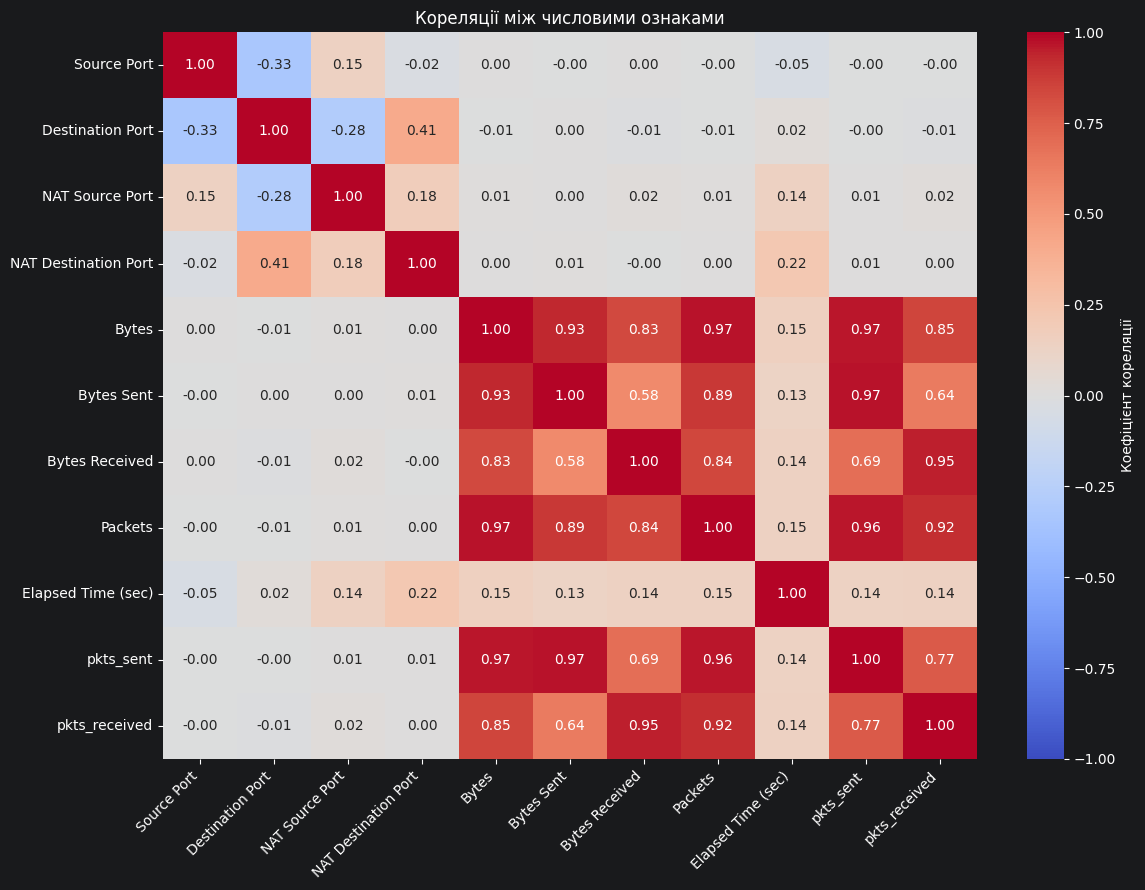

In [28]:
correlation_matrix = X.corr(method="pearson")

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    cbar_kws={"label": "Коефіцієнт кореляції"}
)

plt.title("Кореляції між числовими ознаками")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Теплову карту будуємо, щоб дослідити зв'язки між числовими ознаками та побачити, які з них можуть містити схожу інформацію.

Кожна клітинка показує кореляцію між двома ознаками:
- значення біля +1 означає, що вони зазвичай зростають разом,
- біля −1 - що зі зростанням однієї інша зазвичай зменшується,
- а біля 0 - що виражений лінійний зв’язок відсутній.

Карта допомагає краще зрозуміти структуру даних перед навчанням моделей. Вона показує зв'язки між ознаками, а не їхню важливість для прогнозування цільової змінної Action.

На тепловій карті бачимо сильний додатний зв'язок між обсягом даних і кількістю пакетів: кореляція Bytes і Packets становить приблизно 0,97. Ці ознаки частково описують спільну характеристику - обсяг мережевого обміну. Тривалість з'єднання пов'язана з ними значно слабше.

Далі побудуємо гістограму тривалості мережевих з'єднань, щоб побачити, які значення трапляються найчастіше та як розподілені записи за тривалістю.

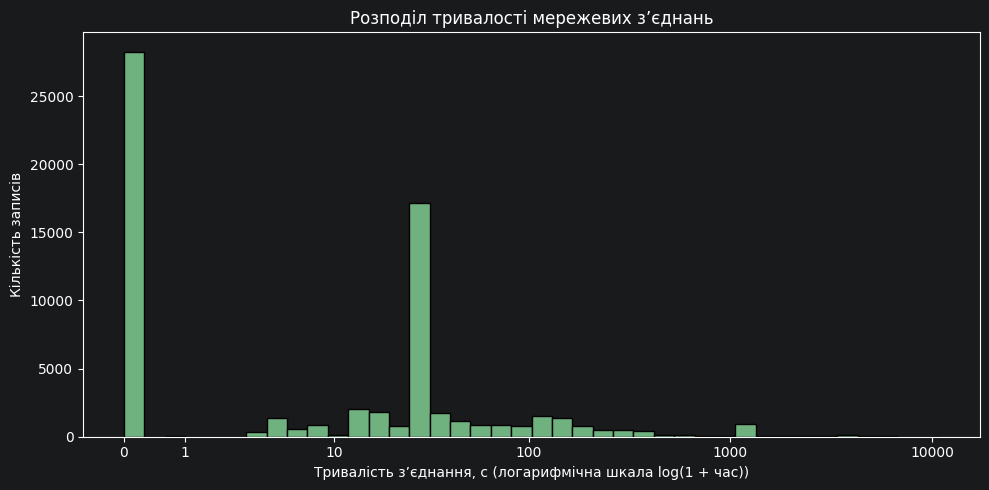

In [29]:
duration_log = np.log1p(df["Elapsed Time (sec)"])

plt.figure(figsize=(10, 5))

sns.histplot(
    x=duration_log,
    bins=40,
    color=sns.color_palette("pastel")[2]
)

time_ticks = [0, 1, 10, 100, 1000, 10000]
plt.xticks(np.log1p(time_ticks), time_ticks)

plt.title("Розподіл тривалості мережевих з’єднань")
plt.xlabel("Тривалість з’єднання, с (логарифмічна шкала log(1 + час))")
plt.ylabel("Кількість записів")
plt.tight_layout()
plt.show()

На початковій гістограмі великі значення тривалості розтягують горизонтальну вісь, через що більшість записів зосереджена в першому інтервалі.
Для детальнішого перегляду будуємо гістограму після перетворення log(1 + час), а підписи осі залишаємо в секундах. Зберігаємо всі записи та не змінюємо початкові дані.

На гістограмі бачимо нерівномірний розподіл тривалості. Багато записів мають нульове значення, а ще один виражений пік розташований у районі кількох десятків секунд. Довгі з'єднання трапляються рідше й утворюють правий хвіст розподілу.

Також побудуємо гістограму загального обсягу даних Bytes, щоб побачити, які обсяги мережевого обміну трапляються найчастіше.


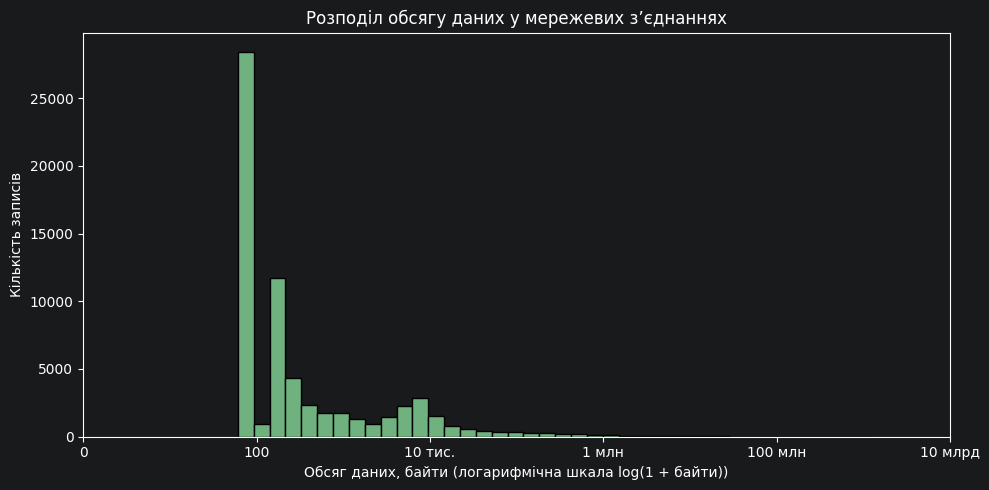

In [30]:
bytes_log = np.log1p(df["Bytes"])

plt.figure(figsize=(10, 5))

sns.histplot(
    x=bytes_log,
    bins=40,
    color=sns.color_palette("pastel")[2]
)

byte_ticks = [0, 100, 10_000, 1_000_000, 100_000_000, 10_000_000_000]
byte_labels = ["0", "100", "10 тис.", "1 млн", "100 млн", "10 млрд"]

plt.xticks(np.log1p(byte_ticks), byte_labels)

plt.title("Розподіл обсягу даних у мережевих з’єднаннях")
plt.xlabel("Обсяг даних, байти (логарифмічна шкала log(1 + байти))")
plt.ylabel("Кількість записів")
plt.tight_layout()
plt.show()

На гістограмі бачимо, що переважають з'єднання з невеликим обсягом даних. Найвираженіший пік розташований у діапазоні менше 100 байтів. Великі обсяги трапляються рідше й утворюють довгий правий хвіст розподілу як довгі з'єднання на попередній гістограмі.

Будуємо гістограму кількості пакетів Packets, щоб побачити, чи переважають з'єднання з малою або великою кількістю пакетів.

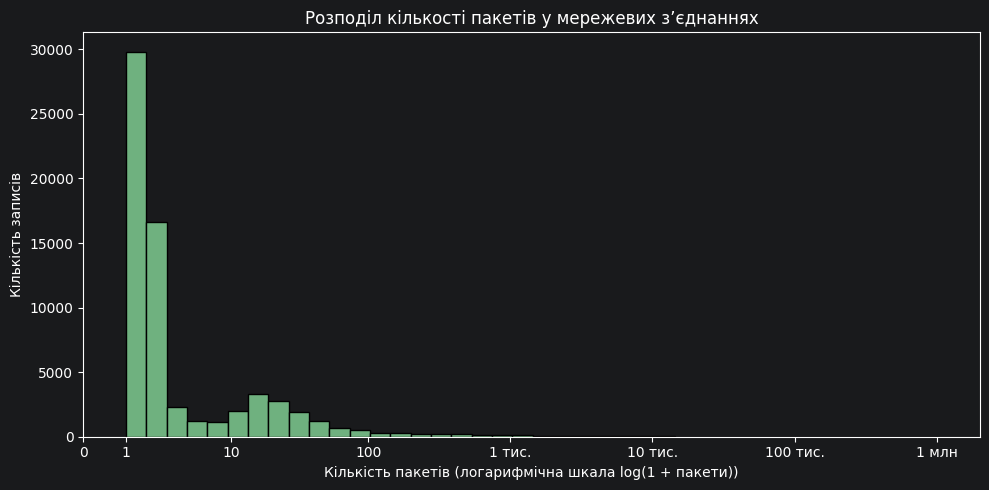

In [31]:
packets_log = np.log1p(df["Packets"])

plt.figure(figsize=(10, 5))

sns.histplot(
    x=packets_log,
    bins=40,
    color=sns.color_palette("pastel")[2]
)

packet_ticks = [0, 1, 10, 100, 1000, 10_000, 100_000, 1_000_000]
packet_labels = ["0", "1", "10", "100", "1 тис.", "10 тис.", "100 тис.", "1 млн"]

plt.xticks(np.log1p(packet_ticks), packet_labels)

plt.title("Розподіл кількості пакетів у мережевих з’єднаннях")
plt.xlabel("Кількість пакетів (логарифмічна шкала log(1 + пакети))")
plt.ylabel("Кількість записів")
plt.tight_layout()
plt.show()

Бачимо, що переважають з'єднання з малою кількістю пакетів, особливо з 1–2 пакетами. Записи зі значно більшою кількістю пакетів трапляються рідше й утворюють
довгий правий хвіст розподілу.

Будуємо boxplot тривалості з'єднання окремо для кожного класу Action. Порівнюємо медіани та розкид значень між класами.

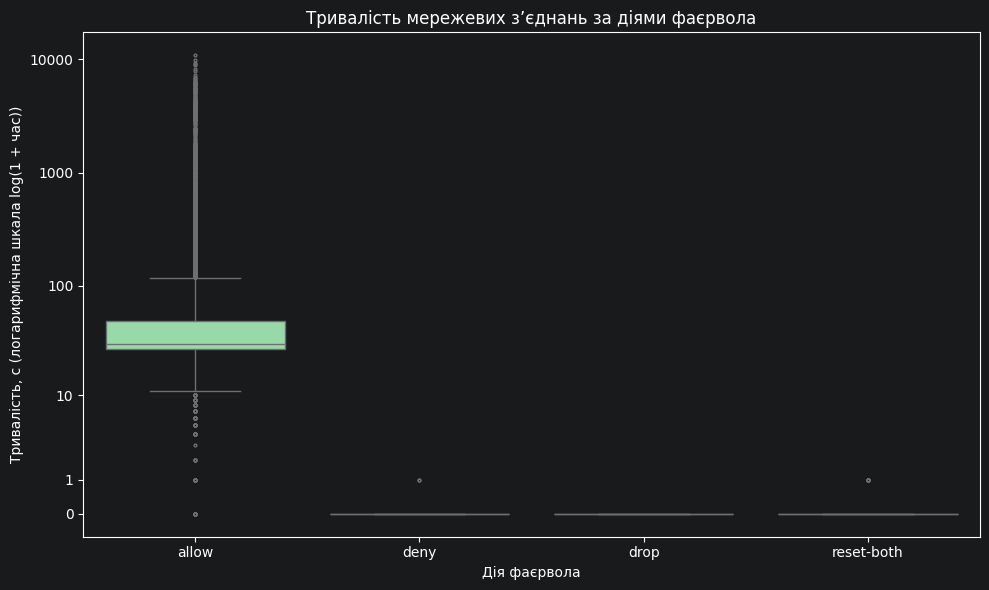

In [32]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=df["Action"],
    y=np.log1p(df["Elapsed Time (sec)"]),
    order=["allow", "deny", "drop", "reset-both"],
    color=sns.color_palette("pastel")[2],
    fliersize=2
)

time_ticks = [0, 1, 10, 100, 1000, 10000]
plt.yticks(np.log1p(time_ticks), time_ticks)

plt.title("Тривалість мережевих з’єднань за діями фаєрвола")
plt.xlabel("Дія фаєрвола")
plt.ylabel("Тривалість, с (логарифмічна шкала log(1 + час))")
plt.tight_layout()
plt.show()

In [33]:
df.groupby("Action")["Elapsed Time (sec)"].describe()

,count,mean,std,min,25%,50%,75%,max
Action,,,,,,,,
allow,37640.0,114.617349,392.025709,0.0,27.0,30.0,49.0,10824.0
deny,14987.0,0.000133,0.011552,0.0,0.0,0.0,0.0,1.0
drop,12851.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
reset-both,54.0,0.129630,0.339050,0.0,0.0,0.0,0.0,1.0


Для класу allow медіана тривалості становить 30 секунд, а середні 50% значень розташовані між 27 і 49 секундами.
Для інших класів переважає нульова тривалість, тому їхні коробки стискаються до рисок. Для drop усі значення дорівнюють нулю.

Будуємо boxplot загального обсягу даних Bytes за класами Action. Порівнюємо медіани та розкид значень, щоб дослідити відмінності між класами.

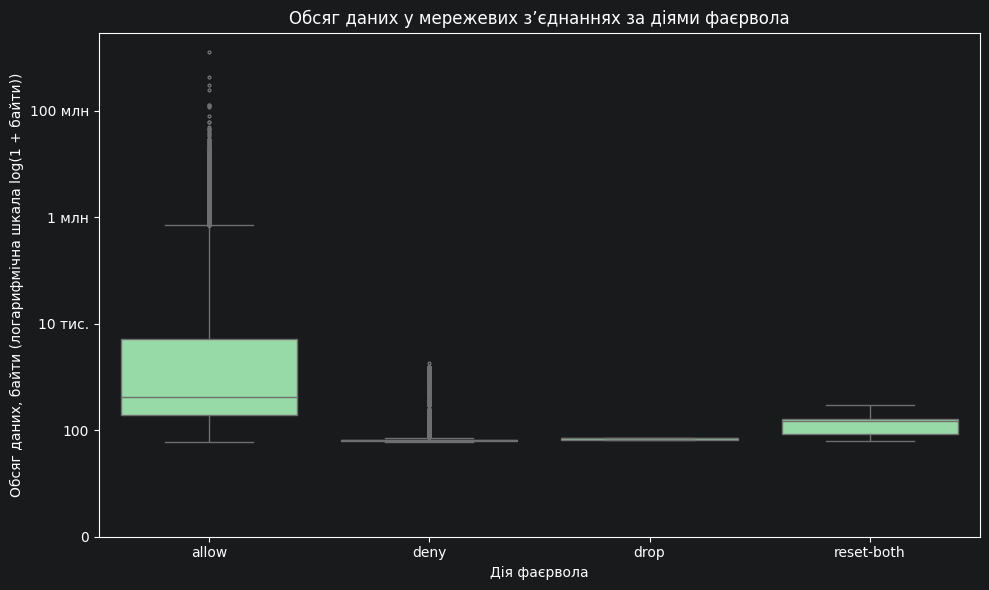

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=df["Action"],
    y=np.log1p(df["Bytes"]),
    order=["allow", "deny", "drop", "reset-both"],
    color=sns.color_palette("pastel")[2],
    fliersize=2
)

byte_ticks = [0, 100, 10_000, 1_000_000, 100_000_000]
byte_labels = ["0", "100", "10 тис.", "1 млн", "100 млн"]

plt.yticks(np.log1p(byte_ticks), byte_labels)

plt.title("Обсяг даних у мережевих з’єднаннях за діями фаєрвола")
plt.xlabel("Дія фаєрвола")
plt.ylabel("Обсяг даних, байти (логарифмічна шкала log(1 + байти))")
plt.tight_layout()
plt.show()

In [35]:
df.groupby("Action")["Bytes"].describe()[["25%", "50%", "75%"]]

,25%,50%,75%
Action,,,
allow,194.00,422.0,5166.0
deny,62.00,66.0,66.0
drop,66.00,70.0,70.0
reset-both,88.75,145.0,158.5


Для класу allow медіана обсягу даних становить 422 байти, а середні 50% значень розташовані між 194 і 5166 байтами. Цей клас має більші і різноманітніші дані.
Для deny та drop медіани становлять 66 і 70 байтів, а коробки вузькі через близькі значення квартилів. Для reset-both медіана дорівнює 145 байтам.

Спостерігаємо відмінності обсягу даних між класами, тому Bytes може бути корисною ознакою для класифікації. Водночас діапазони значень частково перекриваються, тому однієї ознаки може бути недостатньо для точного розпізнавання всіх класів.

### Задача №4
4) Підготовка даних до навчання: розділити дані на training та test вибірки; виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

Розділяємо дані на навчальну (80%) та тестову (20%) вибірки. Зберігаємо приблизно однакові частки класів в обох вибірках оскільки класи незбалансовані. Тестову вибірку залишаємо для фінального оцінювання моделей.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7, stratify=y)

print("Кількість навчальних записів:", len(X_train))
print("Кількість тестових записів:", len(X_test))

print("\nКількість записів кожного класу:")
print(pd.DataFrame({"Навчальна вибірка": y_train.value_counts(),"Тестова вибірка": y_test.value_counts()}))

Кількість навчальних записів: 52425
Кількість тестових записів: 13107

Кількість записів кожного класу:
            Навчальна вибірка  Тестова вибірка
Action                                        
allow                   30112             7528
deny                    11989             2998
drop                    10281             2570
reset-both                 43               11


Завдяки `stratify=y` усі класи потрапили в обидві вибірки приблизно в початкових пропорціях.
Для kNN та SVM використовуємо StandardScaler, оскільки ознаки мають різні одиниці вимірювання й масштаби.

Об'єднуємо масштабування та класифікатор у Pipeline. Це дозволяє обчислювати параметри масштабування лише на навчальних даних, зокрема під час перехресної перевірки. Цільову змінну Action не чіпаємо.

In [37]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())])

knn_pipeline

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

### Задача №5 + №6
5) Навчання моделей - навчити наступні класифікатори:
    - k-Nearest Neighbors (kNN)
    - Decision Tree
    - Support Vector Machine (SVM)
    - Random Forest
    - AdaBoost

6) Підбір гіперпараметрів: для kNN підібрати оптимальне значення n_neighbors, для SVM за допомогою GridSearchCV підібрати оптимальні значення C та gamma. За бажанням можна дослідити вплив гіперпараметрів і для інших моделей.

#### k-Nearest Neighbors (kNN)
Спочатку навчаємо базовий kNN із 5 сусідами. Для прогнозування модель знаходить найближчі навчальні записи та обирає найпоширеніший серед них клас.
Використовуємо Pipeline, який спочатку масштабує ознаки, а потім передає їх класифікатору.

In [38]:
knn_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

Тепер підбираємо кількість сусідів kNN серед значень 1, 3, 5, 7, 11 і 15. Для кожного варіанта використовуємо стратифіковану перехресну перевірку на трьох частинах навчальної вибірки. Обираємо варіант із найбільшим середнім macro-F1, щоб враховувати якість розпізнавання всіх класів незалежно від їхньої кількості.

Pipeline забезпечує навчання масштабування окремо всередині кожного розбиття лише на його навчальній частині.

In [39]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=7)

knn_search = GridSearchCV(estimator=knn_pipeline, param_grid={"model__n_neighbors": [1, 3, 5, 7, 11, 15]},
                          scoring="f1_macro", cv=cv, n_jobs=2, refit=True
)

knn_search.fit(X_train, y_train)

knn_results = pd.DataFrame({
    "Кількість сусідів": knn_search.cv_results_["param_model__n_neighbors"],
    "Середній macro-F1": knn_search.cv_results_["mean_test_score"],
    "Стандартне відхилення": knn_search.cv_results_["std_test_score"]
})

knn_best = knn_search.best_estimator_
print("Найкраща кількість сусідів:", knn_search.best_params_["model__n_neighbors"])
print("Найкращий середній macro-F1:", round(knn_search.best_score_, 4))

knn_results.sort_values("Середній macro-F1", ascending=False)

Найкраща кількість сусідів: 1
Найкращий середній macro-F1: 0.7616


,Кількість сусідів,Середній macro-F1,Стандартне відхилення
0,1,0.761633,0.010696
1,3,0.756850,0.013747
2,5,0.746561,0.000254
3,7,0.746077,0.000325
4,11,0.744399,0.000642
5,15,0.743045,0.000787


Серед перевірених значень кількості сусідів найкращий середній macro-F1 отримали при `n_neighbors=1`: приблизно 0,7616. Для подальшого оцінювання обираємо цей варіант. Зі збільшенням кількості сусідів середній macro-F1 зменшувався.

Можливе пояснення: дальші сусіди інших класів можуть змінювати результат голосування, зокрема для рідкісних класів. Для підтвердження цієї причини потрібен окремий аналіз помилок.

Перевага над n_neighbors=3 невелика, тому результат не вважаємо універсальним. Остаточну якість обраної моделі перевіримо
на відкладеній тестовій вибірці.

#### Decision Tree

Далі навчаємо дерево рішень, яке послідовно розділяє записи за значеннями ознак. Ознаки та пороги для розділення алгоритм обирає під час навчання.

Масштабування не застосовуємо, оскільки дерево використовує порогові порівняння окремих ознак.

In [40]:
tree_model = DecisionTreeClassifier(random_state=7)
tree_model.fit(X_train, y_train)

print("Глибина дерева:", tree_model.get_depth())
print("Кількість листків:", tree_model.get_n_leaves())

Глибина дерева: 21
Кількість листків: 137


Після навчання отримуємо дерево глибиною 21 із 137 листками. Отже, найдовший шлях до прогнозу містить 21 перевірку, а навчальні записи розподілено на 137 кінцевих груп, кількість класів при цьому залишається рівною чотирьом.

Глибину дерева явно не обмежуємо. Отримана структура дозволяє враховувати детальні відмінності між записами, але може підлаштовуватися під особливості навчальних даних. За глибиною та кількістю листків не визначаємо якість моделі, її перевіримо окремо на тестовій вибірці.

#### Support Vector Machine (SVM)

Навчаємо SVM із ядром RBF, яке дозволяє будувати нелінійні межі між класами. Перед класифікатором застосовуємо StandardScaler через Pipeline.
Спочатку навчаємо базову модель та вимірюємо час навчання, щоб оцінити тривалість подальшого підбору параметрів.

In [41]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale"))])

start_time = perf_counter()

svm_pipeline.fit(X_train, y_train)

training_time = perf_counter() - start_time

print("Навчання базової SVM завершено")
print(f"Час навчання: {training_time:.2f} с")

Навчання базової SVM завершено
Час навчання: 18.01 с


За допомогою GridSearchCV підбираємо параметри `C` та `gamma`. Перевіряємо дев'ять комбінацій зі стратифікованою перехресною перевіркою на трьох частинах. Найкращу комбінацію обираємо за середнім macro-F1.

In [42]:
svm_search = GridSearchCV(estimator=svm_pipeline,
                          param_grid={"model__C": [0.1, 1, 10], "model__gamma": [0.01, 0.1, 1]},
                          scoring="f1_macro", cv=cv, n_jobs=2, refit=True, verbose=1)

start_time = perf_counter()

svm_search.fit(X_train, y_train)

search_time = perf_counter() - start_time
svm_best = svm_search.best_estimator_

svm_results = pd.DataFrame({
    "C": svm_search.cv_results_["param_model__C"],
    "gamma": svm_search.cv_results_["param_model__gamma"],
    "Середній macro-F1": svm_search.cv_results_["mean_test_score"],
    "Стандартне відхилення": svm_search.cv_results_["std_test_score"]})

print("Найкраще C:", svm_search.best_params_["model__C"])
print("Найкраще gamma:", svm_search.best_params_["model__gamma"])
print("Найкращий середній macro-F1:", round(svm_search.best_score_, 4))
print(f"Час підбору та навчання найкращої моделі: {search_time:.2f} с")

svm_results.sort_values("Середній macro-F1", ascending=False)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Найкраще C: 10
Найкраще gamma: 1
Найкращий середній macro-F1: 0.7426
Час підбору та навчання найкращої моделі: 253.02 с


,C,gamma,Середній macro-F1,Стандартне відхилення
8,10.0,1.00,0.742568,0.000805
5,1.0,1.00,0.741674,0.000789
7,10.0,0.10,0.741346,0.000975
4,1.0,0.10,0.734930,0.000879
6,10.0,0.01,0.734803,0.000692
2,0.1,1.00,0.734485,0.000953
1,0.1,0.10,0.722008,0.000881
3,1.0,0.01,0.720909,0.000518
0,0.1,0.01,0.677421,0.000362


Серед дев'яти перевірених комбінацій найкращий результат отримуємо при `C=10` та `gamma=1`: середній macro-F1 становить приблизно 0,7426.
Обрана комбінація передбачає сильніший штраф за помилки та більш локальний вплив навчальних прикладів порівняно з меншими перевіреними значеннями параметрів.
Перевага над наступною комбінацією невелика.

Обидва параметри лежать на верхній межі перевіреної сітки, тому вважаємо їх найкращими лише серед досліджених варіантів. Обрану модель зберігаємо у `svm_best` для подальшого оцінювання на тестовій вибірці.

#### Random Forest

Навчаємо випадковий ліс зі 100 дерев рішень. Кожне дерево використовує випадкову вибірку навчальних записів із повтореннями, а під час розділень розглядає випадкову частину ознак.
Підсумковий клас визначаємо за усередненими ймовірностями класів від усіх дерев. Це зменшує залежність прогнозу від особливостей одного дерева. Масштабування не застосовуємо.

In [43]:
forest_model = RandomForestClassifier(n_estimators=100, random_state=7, n_jobs=2)

start_time = perf_counter()

forest_model.fit(X_train, y_train)

forest_training_time = perf_counter() - start_time

print("Кількість дерев:", len(forest_model.estimators_))
print(f"Час навчання: {forest_training_time:.2f} с")

Кількість дерев: 100
Час навчання: 1.72 с


#### AdaBoost

Навчаємо AdaBoost із простими деревами глибиною 1. Моделі навчаються послідовно: після кожного кроку збільшуємо увагу до записів, які були класифіковані неправильно.

Підсумковий прогноз отримуємо шляхом зваженого поєднання відповідей моделей. Задаємо до 50 дерев. Масштабування не застосовуємо, оскільки базовими моделями
є дерева рішень.

In [44]:
adaboost_model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                    n_estimators=50, learning_rate=1.0, random_state=7)

start_time = perf_counter()

adaboost_model.fit(X_train, y_train)

adaboost_training_time = perf_counter() - start_time

print("Фактична кількість дерев:", len(adaboost_model.estimators_))
print(f"Час навчання: {adaboost_training_time:.2f} с")

Фактична кількість дерев: 50
Час навчання: 3.35 с


### Задача №7

Порівняння та оцінювання моделей
Порівняти результати всіх навчених класифікаторів та визначити найкращу модель для обраного датасета.
Для моделей вивести та проаналізувати:
- sklearn.metrics.classification_report
- sklearn.metrics.confusion_matrix


#### Оцінювання kNN

Отримаємо прогнози налаштованого kNN на тестовій вибірці та порівнюємо їх зі справжніми класами. Використовуємо модель з `n_neighbors=1`, обрану під час перехресної перевірки.

In [45]:
knn_predictions = knn_best.predict(X_test)

prediction_examples = pd.DataFrame({
    "Справжній клас": y_test,
    "Прогноз kNN": knn_predictions})

class_order = ["allow", "deny", "drop", "reset-both"]

print("Звіт про якість kNN на тестовій вибірці:")
print(classification_report(y_test, knn_predictions, labels=class_order,
                            digits=4, zero_division=0))

print("\nПриклади прогнозів:")
prediction_examples.head(10)

Звіт про якість kNN на тестовій вибірці:
              precision    recall  f1-score   support

       allow     0.9991    0.9993    0.9992      7528
        deny     0.9923    0.9943    0.9933      2998
        drop     0.9965    0.9953    0.9959      2570
  reset-both     0.3333    0.1818    0.2353        11

    accuracy                         0.9967     13107
   macro avg     0.8303    0.7927    0.8059     13107
weighted avg     0.9965    0.9967    0.9966     13107


Приклади прогнозів:


,Справжній клас,Прогноз kNN
27423,allow,allow
10818,allow,allow
39267,allow,allow
42901,deny,deny
39078,deny,deny
1785,drop,drop
45680,allow,allow
4190,deny,deny
26131,allow,allow
45549,deny,deny


На тестовій вибірці kNN отримує accuracy приблизно 99,67% та macro-F1 близько 0,8059. Для класів allow, deny та drop значення F1 перевищують 0,99.

Найгірше модель розпізнає рідкісний клас reset-both. Правильно визначає лише 2 з 11 записів, тому recall становить 0,1818. Серед 6 прогнозів цього класу правильними є 2, отже precision дорівнює 0,3333, а F1 - 0,2353.

Висока загальна точність не відображає проблеми розпізнавання рідкісного класу. Тому під час порівняння моделей враховуємо macro-F1 та показники кожного класу. Оцінка reset-both чутлива до окремих помилок через малу кількість тестових записів.

Будуємо матрицю помилок kNN, щоб визначити, які класи модель плутає між собою. Рядки відповідають справжнім класам, а стовпці прогнозованим. На головній діагоналі розташовані правильні прогнози, поза нею - помилки.

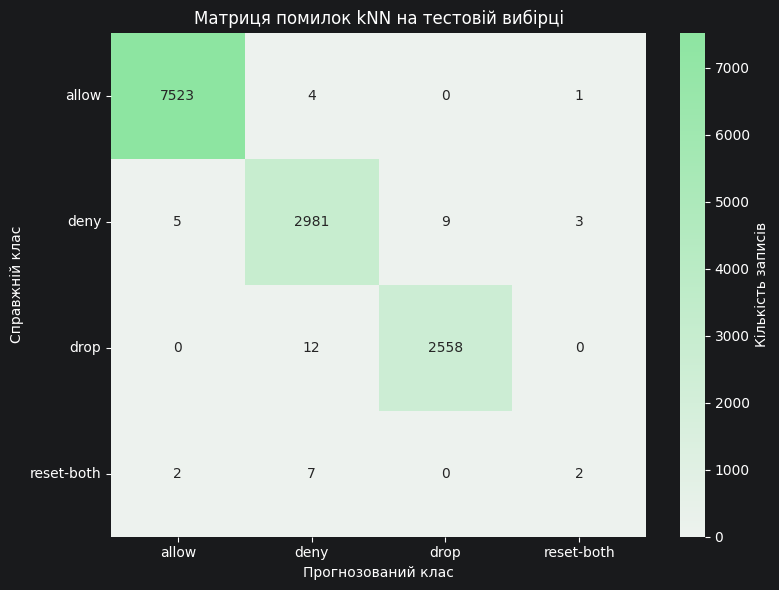

In [46]:
knn_matrix = confusion_matrix(y_test, knn_predictions, labels=class_order)

plt.figure(figsize=(8, 6))

sns.heatmap(knn_matrix, annot=True, fmt="d",
            cmap=sns.light_palette(sns.color_palette("pastel")[2], as_cmap=True),
            xticklabels=class_order, yticklabels=class_order, cbar_kws={"label": "Кількість записів"})

plt.title("Матриця помилок kNN на тестовій вибірці")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Матриця помилок показує, що з 11 записів класу reset-both модель правильно визначає 2, помилково відносить 7 до deny та 2 до allow. Отже, найчастіше цей клас плутається з deny.

Також модель помилково прогнозує reset-both для одного запису allow та трьох записів deny. Це пояснює низькі precision і recall класу reset-both у classification_report.

#### Оцінювання Decision Tree

Отримуємо прогнози дерева рішень на тій самій тестовій вибірці, яку використовуємо для kNN. Аналізуємо classification_report та матрицю помилок, приділяючи особливу увагу рідкісному класу reset-both.

Звіт про якість Decision Tree на тестовій вибірці:
              precision    recall  f1-score   support

       allow     1.0000    0.9992    0.9996      7528
        deny     0.9920    0.9963    0.9942      2998
        drop     0.9973    0.9949    0.9961      2570
  reset-both     0.6000    0.5455    0.5714        11

    accuracy                         0.9973     13107
   macro avg     0.8973    0.8840    0.8903     13107
weighted avg     0.9973    0.9973    0.9973     13107



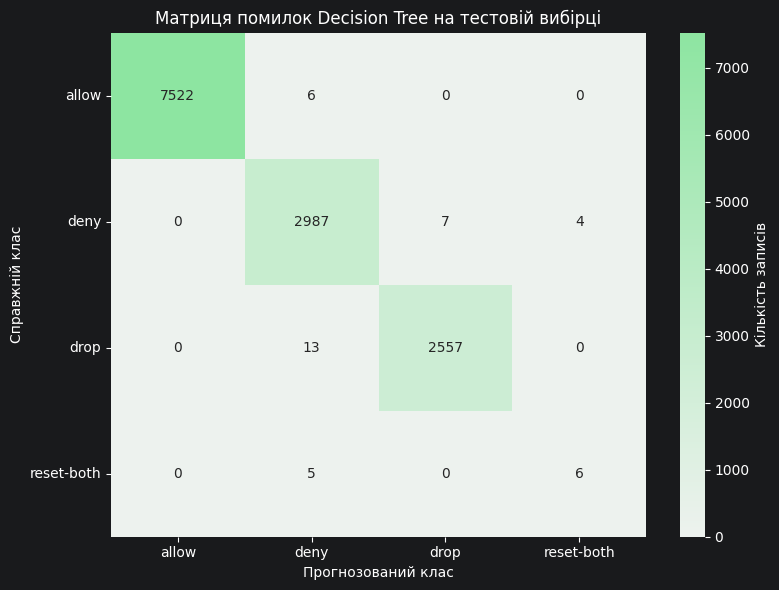

In [47]:
tree_predictions = tree_model.predict(X_test)

print("Звіт про якість Decision Tree на тестовій вибірці:")
print(classification_report(y_test, tree_predictions, labels=class_order, digits=4, zero_division=0))

tree_matrix = confusion_matrix(y_test, tree_predictions, labels=class_order)

plt.figure(figsize=(8, 6))

sns.heatmap(tree_matrix, annot=True, fmt="d",
            cmap=sns.light_palette(sns.color_palette("pastel")[2], as_cmap=True),
            xticklabels=class_order, yticklabels=class_order, cbar_kws={"label": "Кількість записів"}
)

plt.title("Матриця помилок Decision Tree на тестовій вибірці")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

На тестовій вибірці Decision Tree отримує accuracy приблизно 99,73% та macro-F1 0,8903, перевищуючи результати kNN. Загальна кількість помилок зменшується з 43 до 35.

Найпомітніше покращується розпізнавання reset-both. Дерево правильно визначає 6 із 11 записів, тоді як kNN - лише 2. F1 цього класу зростає з 0,2353 до 0,5714. Решту 5 записів reset-both дерево помилково відносить до deny.

Отже, у цьому експерименті дерево краще розпізнає рідкісний клас, хоча проблема його змішування з deny залишається. Через малу кількість тестових записів reset-both результат потребує обережного узагальнення.

#### Оцінювання SVM

Оцінюємо SVM із параметрами `C=10` та `gamma=1`, обраними за результатами перехресної перевірки.

Звіт про якість SVM на тестовій вибірці:
              precision    recall  f1-score   support

       allow     0.9993    0.9968    0.9981      7528
        deny     0.9892    0.9760    0.9825      2998
        drop     0.9735    1.0000    0.9866      2570
  reset-both     0.0000    0.0000    0.0000        11

    accuracy                         0.9918     13107
   macro avg     0.7405    0.7432    0.7418     13107
weighted avg     0.9911    0.9918    0.9914     13107



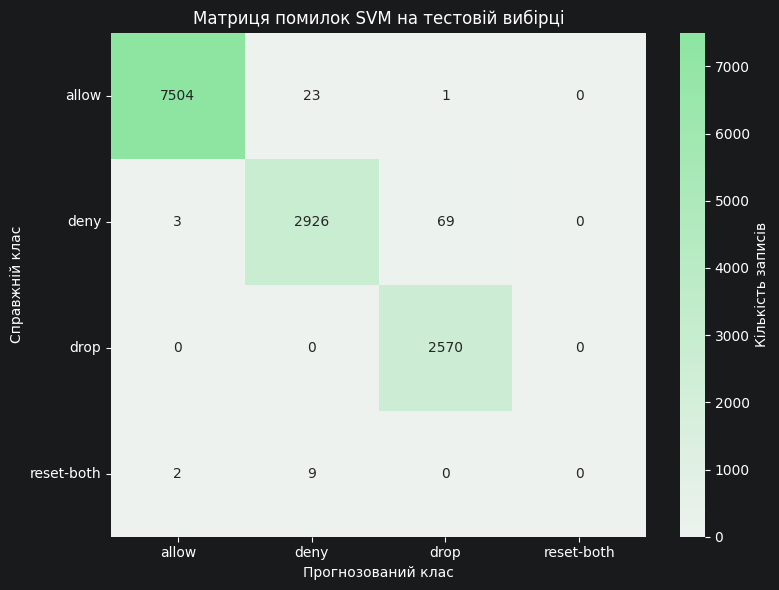

In [48]:
svm_predictions = svm_best.predict(X_test)

print("Звіт про якість SVM на тестовій вибірці:")
print(classification_report(y_test, svm_predictions, labels=class_order, digits=4, zero_division=0))

svm_matrix = confusion_matrix(y_test, svm_predictions, labels=class_order)

plt.figure(figsize=(8, 6))

sns.heatmap(svm_matrix, annot=True, fmt="d",
            cmap=sns.light_palette(sns.color_palette("pastel")[2], as_cmap=True),
            xticklabels=class_order, yticklabels=class_order, cbar_kws={"label": "Кількість записів"}
)

plt.title("Матриця помилок SVM на тестовій вибірці")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

На тестовій вибірці для SVM отримуємо accuracy 99,18% та macro-F1 0,7418 - найнижчі значення серед трьох уже оцінених моделей.

За матрицею помилок бачимо, що SVM жодного разу не прогнозує reset-both, а із 11 справжніх записів цього класу 9 відносить до deny, 2 до allow. Для порівняння, kNN розпізнає 2 з 11, а дерево рішень 6 з 11. Висока загальна accuracy у цьому випадку приховує те, що один із чотирьох класів модель не розпізнає.

#### Оцінювання Random Forest

Оцінюємо випадковий ліс.

Звіт про якість Random Forest на тестовій вибірці:
              precision    recall  f1-score   support

       allow     1.0000    0.9997    0.9999      7528
        deny     0.9927    0.9977    0.9952      2998
        drop     0.9973    0.9953    0.9963      2570
  reset-both     1.0000    0.2727    0.4286        11

    accuracy                         0.9978     13107
   macro avg     0.9975    0.8164    0.8550     13107
weighted avg     0.9978    0.9978    0.9976     13107



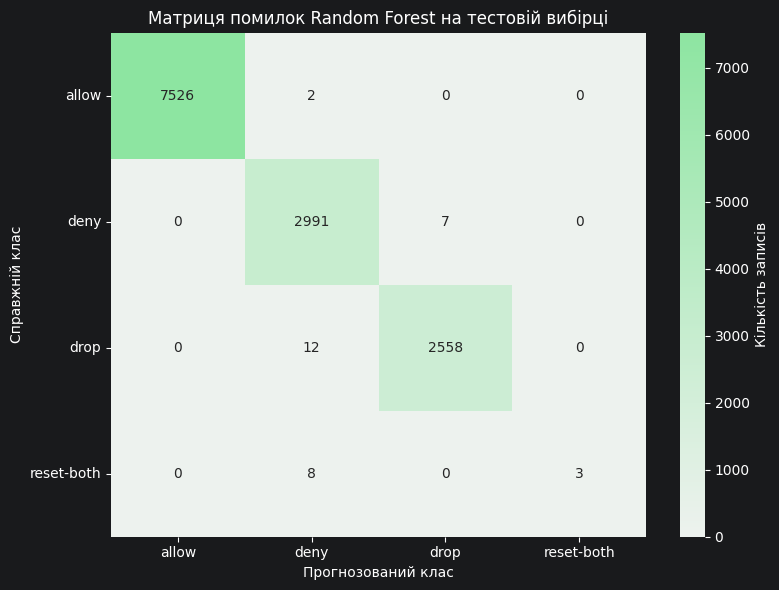

In [49]:
forest_predictions = forest_model.predict(X_test)

print("Звіт про якість Random Forest на тестовій вибірці:")
print(classification_report(y_test, forest_predictions, labels=class_order, digits=4, zero_division=0))

forest_matrix = confusion_matrix(y_test, forest_predictions, labels=class_order)

plt.figure(figsize=(8, 6))
sns.heatmap(forest_matrix, annot=True, fmt="d",
            cmap=sns.light_palette(sns.color_palette("pastel")[2], as_cmap=True),
            xticklabels=class_order, yticklabels=class_order, cbar_kws={"label": "Кількість записів"}
)
plt.title("Матриця помилок Random Forest на тестовій вибірці")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

На тестовій вибірці для Random Forest отримуємо accuracy 99,78%. Ліс робить 29 помилок проти 35 в одного дерева. Проте з 11 записів reset-both ліс розпізнає лише 3, а решту 8 відносить до deny. Усі три прогнози reset-both правильні, тому precision цього класу становить 1,00, хоча recall - лише 0,2727.

Одне дерево знаходить 6 із 11 записів reset-both. За критерієм macro-F1 кращий результат на цій вибірці отримуємо для одного дерева 0,8903 проти 0,8550 у Random Forest.

#### Оцінювання AdaBoost

Оцінюємо AdaBoost на тій самій тестовій вибірці

Звіт про якість AdaBoost на тестовій вибірці:
              precision    recall  f1-score   support

       allow     0.9999    0.9989    0.9994      7528
        deny     0.9940    0.9970    0.9955      2998
        drop     0.9969    1.0000    0.9984      2570
  reset-both     1.0000    0.0909    0.1667        11

    accuracy                         0.9979     13107
   macro avg     0.9977    0.7717    0.7900     13107
weighted avg     0.9979    0.9979    0.9976     13107



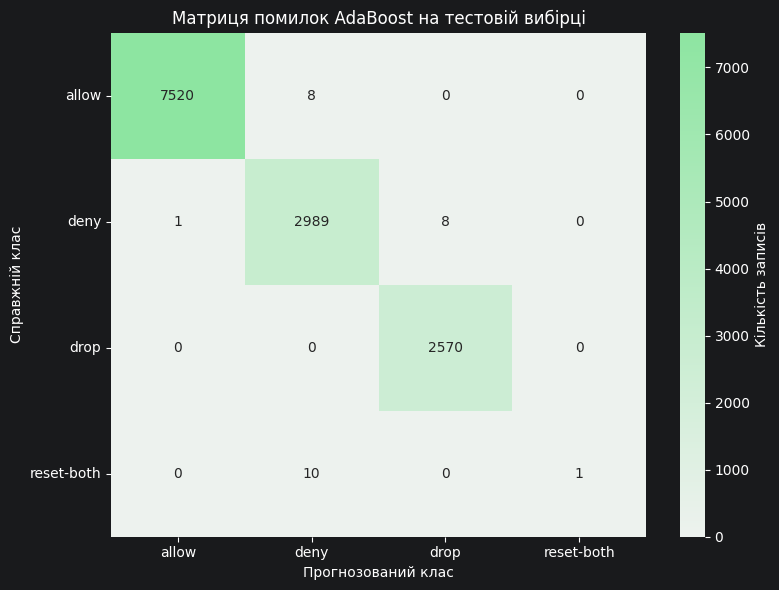

In [50]:
adaboost_predictions = adaboost_model.predict(X_test)

print("Звіт про якість AdaBoost на тестовій вибірці:")
print(classification_report(y_test, adaboost_predictions, labels=class_order, digits=4, zero_division=0))

adaboost_matrix = confusion_matrix(y_test, adaboost_predictions, labels=class_order)

plt.figure(figsize=(8, 6))
sns.heatmap(adaboost_matrix, annot=True, fmt="d",
            cmap=sns.light_palette(sns.color_palette("pastel")[2], as_cmap=True),
            xticklabels=class_order, yticklabels=class_order, cbar_kws={"label": "Кількість записів"})

plt.title("Матриця помилок AdaBoost на тестовій вибірці")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Для AdaBoost отримуємо найвищу загальну accuracy - 99,79%. Водночас модель розпізнає лише 1 із 11 записів reset-both, а решту 10 відносить до deny. Для цього рідкісного класу кращий результат показують одне дерево (6 із 11) та випадковий ліс (3 із 11).

#### Порівняння всіх моделей

In [51]:
model_predictions = {
    "kNN": knn_predictions,
    "Decision Tree": tree_predictions,
    "SVM": svm_predictions,
    "Random Forest": forest_predictions,
    "AdaBoost": adaboost_predictions}

rows = []

for model_name, predictions in model_predictions.items():
    report = classification_report(
        y_test, predictions, output_dict=True, zero_division=0
    )
    found_reset = ((y_test == "reset-both") & (predictions == "reset-both")).sum()

    rows.append({
        "Модель": model_name,
        "Accuracy, %": 100 * report["accuracy"],
        "Macro-F1": report["macro avg"]["f1-score"],
        "F1 для reset-both": report["reset-both"]["f1-score"],
        "Знайдено reset-both": found_reset
    })

comparison = pd.DataFrame(rows).set_index("Модель").sort_values(
    "Macro-F1", ascending=False
)
comparison.round({"Accuracy, %": 2, "Macro-F1": 4, "F1 для reset-both": 4})

,"Accuracy, %",Macro-F1,F1 для reset-both,Знайдено reset-both
Модель,,,,
Decision Tree,99.73,0.8903,0.5714,6
Random Forest,99.78,0.8550,0.4286,3
kNN,99.67,0.8059,0.2353,2
AdaBoost,99.79,0.7900,0.1667,1
SVM,99.18,0.7418,0.0000,0


За основним критерієм macro-F1 обираємо Decision Tree (0,8903). Дерево добре розпізнає три поширені класи та знаходить 6 із 11 записів reset-both - найбільше серед п’яти моделей. AdaBoost має вищу загальну accuracy, але пропускає 10 із цих 11 записів.

Для reset-both маємо лише 11 прикладів, тому навіть один прогноз помітно впливає на оцінку цього класу.

Припускаємо, що дерево добре підходить цим даним, бо може послідовно перевіряти пороги окремих ознак. Наприклад, під час EDA бачимо, що медіана тривалості для `allow` становить 30 секунд, а для інших класів - 0. Така відмінність пояснює, чому порогові правила можуть бути корисними, хоча конкретні правила навченого дерева ми не аналізували.